# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
import plotly.io as pio
pio.renderers.default = 'plotly_mimetype+notebook_connected+png'

import numpy as np
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   continent  1704 non-null   str    
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   str    
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 135.3 KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: <ArrowStringArray>
['Asia', 'Europe', 'Africa', 'Americas', 'Oceania']
Length: 5, dtype: str
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.

## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


Richer and longer-lived: 30 of 30 countries
Median GDP growth: poorer half 29%, richer half 11%


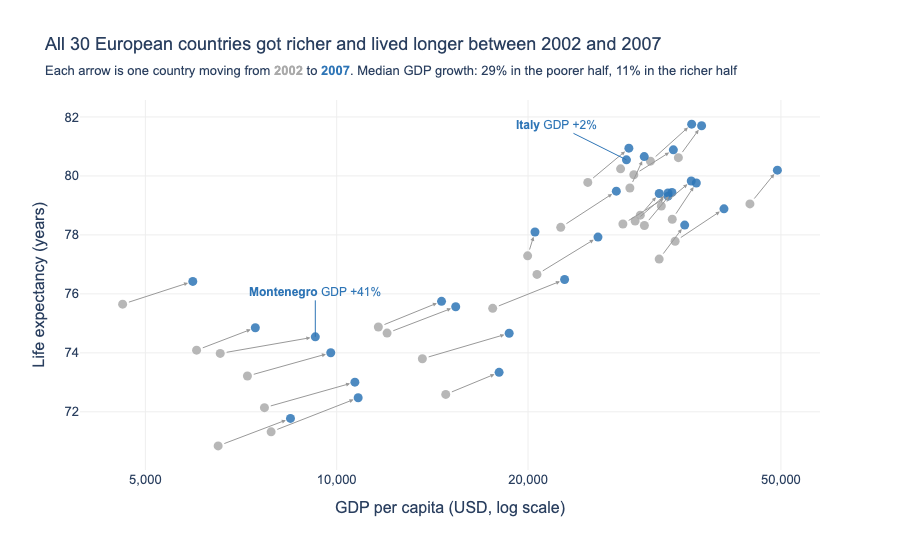

In [3]:
# Task 1 — Europe, 2002 vs 2007
continent = 'Europe'
data = df[(df['continent'] == continent) & df['year'].isin([2002, 2007])]
data = data.assign(Year=data['year'].astype(str))

gdp = data.pivot(index='country', columns='year', values='gdpPercap')
life = data.pivot(index='country', columns='year', values='lifeExp')
growth = (gdp[2007] / gdp[2002] - 1) * 100
both_up = ((gdp[2007] > gdp[2002]) & (life[2007] > life[2002])).sum()
poorer = gdp[2002] < gdp[2002].median()
fastest, slowest = growth.idxmax(), growth.idxmin()
print(f"Richer and longer-lived: {both_up} of {len(gdp)} countries")
print(f"Median GDP growth: poorer half {growth[poorer].median():.0f}%, richer half {growth[~poorer].median():.0f}%")

fig = px.scatter(
    data_frame=data,
    x='gdpPercap', y='lifeExp',
    color='Year',
    color_discrete_map={'2002': '#AAAAAA', '2007': '#2E75B6'},
    hover_name='country',
    log_x=True,
    labels={'gdpPercap': 'GDP per capita (USD, log scale)', 'lifeExp': 'Life expectancy (years)'},
    template='plotly_white',
    height=550, width=900
)

fig.update_traces(marker=dict(size=9, opacity=0.85), showlegend=False)

# one arrow per country: where it was in 2002 -> where it is in 2007
for country in gdp.index:
    fig.add_annotation(
        x=np.log10(gdp.loc[country, 2007]), y=life.loc[country, 2007],
        ax=np.log10(gdp.loc[country, 2002]), ay=life.loc[country, 2002],
        axref='x', ayref='y', text='',
        showarrow=True, arrowhead=2, arrowsize=0.8, arrowwidth=1, arrowcolor='#999999',
        standoff=5, startstandoff=5
    )

for country, ax, ay in [(fastest, 0, -45), (slowest, -70, -35)]:
    fig.add_annotation(
        x=np.log10(gdp.loc[country, 2007]), y=life.loc[country, 2007],
        text=f"<b>{country}</b> GDP +{growth[country]:.0f}%",
        showarrow=True, arrowhead=0, arrowwidth=1, arrowcolor='#2E75B6', ax=ax, ay=ay,
        font=dict(size=12, color='#2E75B6')
    )

fig.update_layout(
    title=dict(
        text=f"All {len(gdp)} European countries got richer and lived longer between 2002 and 2007",
        subtitle=dict(text=(
            "Each arrow is one country moving from <span style='color:#AAAAAA'><b>2002</b></span> to "
            "<span style='color:#2E75B6'><b>2007</b></span>. Median GDP growth: "
            f"{growth[poorer].median():.0f}% in the poorer half, {growth[~poorer].median():.0f}% in the richer half"
        ))
    ),
    font=dict(family='Arial', size=13),
    xaxis=dict(gridcolor='#EEEEEE', tickvals=[5000, 10000, 20000, 50000], tickformat=','),
    yaxis=dict(gridcolor='#EEEEEE'),
    margin=dict(t=100)
)

fig.show()

## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


Life expectancy gap within each continent (years):
continent
Asia        38.8
Africa      36.8
Americas    19.7
Europe      10.0
Oceania      1.0
Name: lifeExp, dtype: float64
Asia's share of population: 61%


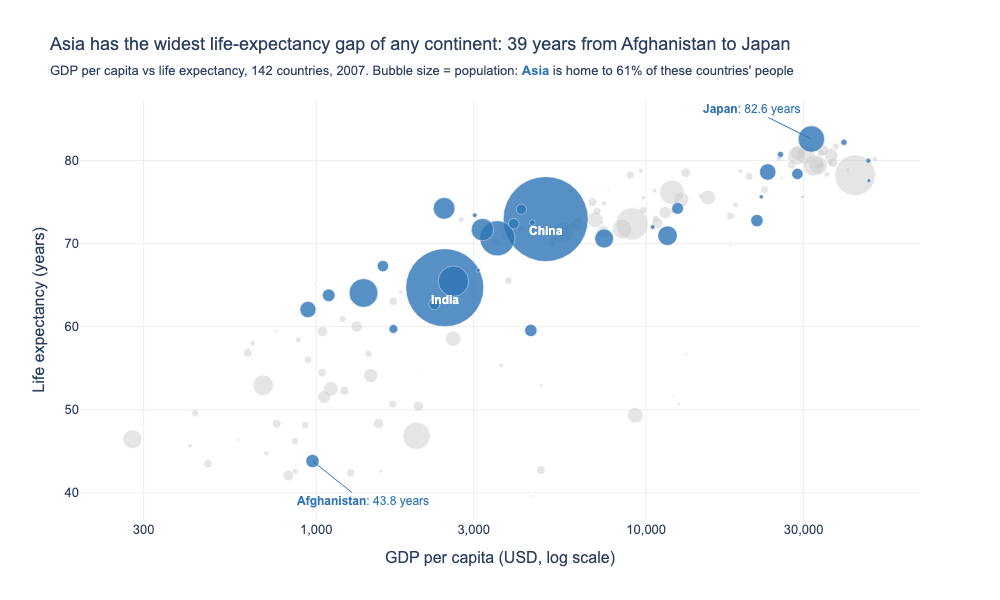

In [4]:
# Task 2 — 2007 bubble chart, Asia highlighted
highlight = 'Asia'
data = df[df['year'] == 2007]
others = sorted(c for c in data['continent'].unique() if c != highlight)
asia = data[data['continent'] == highlight].set_index('country')

life_gap = data.groupby('continent')['lifeExp'].agg(lambda s: s.max() - s.min()).sort_values(ascending=False)
pop_share = asia['pop'].sum() / data['pop'].sum()
longest, shortest = asia['lifeExp'].idxmax(), asia['lifeExp'].idxmin()
print("Life expectancy gap within each continent (years):")
print(life_gap.round(1))
print(f"Asia's share of population: {pop_share:.0%}")

fig = px.scatter(
    data_frame=data,
    x='gdpPercap', y='lifeExp',
    size='pop', size_max=60,
    color='continent',
    category_orders={'continent': others + [highlight]},
    color_discrete_map={**{c: '#CCCCCC' for c in others}, highlight: '#2E75B6'},
    hover_name='country',
    hover_data={'continent': True, 'pop': ':,'},
    log_x=True,
    labels={'gdpPercap': 'GDP per capita (USD, log scale)', 'lifeExp': 'Life expectancy (years)',
            'pop': 'Population', 'continent': 'Continent'},
    template='plotly_white',
    height=600, width=1000
)

fig.update_traces(marker=dict(opacity=0.5, line=dict(width=0.5, color='white')), showlegend=False)
fig.update_traces(marker=dict(opacity=0.8), selector=dict(name=highlight))

for country, ax, ay in [(longest, -60, -30), (shortest, 50, 40)]:
    fig.add_annotation(
        x=np.log10(asia.loc[country, 'gdpPercap']), y=asia.loc[country, 'lifeExp'],
        text=f"<b>{country}</b>: {asia.loc[country, 'lifeExp']:.1f} years",
        showarrow=True, arrowhead=0, arrowwidth=1, arrowcolor='#2E75B6', ax=ax, ay=ay,
        font=dict(size=12, color='#2E75B6')
    )

# the two biggest bubbles are labelled inside
for country in asia['pop'].nlargest(2).index:
    fig.add_annotation(
        x=np.log10(asia.loc[country, 'gdpPercap']), y=asia.loc[country, 'lifeExp'],
        text=f"<b>{country}</b>", showarrow=False, yshift=-12,
        font=dict(size=12, color='white')
    )

fig.update_layout(
    title=dict(
        text=f"Asia has the widest life-expectancy gap of any continent: {life_gap[highlight]:.0f} years "
             f"from {shortest} to {longest}",
        subtitle=dict(text=(
            f"GDP per capita vs life expectancy, {len(data)} countries, 2007. Bubble size = population: "
            f"<span style='color:#2E75B6'><b>Asia</b></span> is home to {pop_share:.0%} of these countries' people"
        ))
    ),
    font=dict(family='Arial', size=13),
    xaxis=dict(gridcolor='#EEEEEE', tickvals=[300, 1000, 3000, 10000, 30000], tickformat=','),
    yaxis=dict(gridcolor='#EEEEEE'),
    margin=dict(t=100)
)

fig.show()